In [1]:
import numpy as np

# Training data: study hours and marks
X = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([20, 40, 60, 80, 100], dtype=float)

# Initialize parameters
w = 0.0
b = 0.0

learning_rate = 0.01
epochs = 1000
n = len(X)

for epoch in range(epochs):
    # Predictions
    y_pred = w * X + b

    # Calculate gradients
    dw = (2 / n) * np.sum((y_pred - y) * X)
    db = (2 / n) * np.sum(y_pred - y)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

print("Weight:", w)
print("Bias:", b)
print("Prediction for 6 hours:", w * 6 + b)

Weight: 19.95180350671978
Bias: 0.1740046334061063
Prediction for 6 hours: 119.88482567372479


Step  1: Gradient =  -6.0000, Weight = 0.600000, Loss = 5.760000
Step  2: Gradient =  -4.8000, Weight = 1.080000, Loss = 3.686400
Step  3: Gradient =  -3.8400, Weight = 1.464000, Loss = 2.359296
Step  4: Gradient =  -3.0720, Weight = 1.771200, Loss = 1.509949
Step  5: Gradient =  -2.4576, Weight = 2.016960, Loss = 0.966368
Step  6: Gradient =  -1.9661, Weight = 2.213568, Loss = 0.618475
Step  7: Gradient =  -1.5729, Weight = 2.370854, Loss = 0.395824
Step  8: Gradient =  -1.2583, Weight = 2.496684, Loss = 0.253327
Step  9: Gradient =  -1.0066, Weight = 2.597347, Loss = 0.162130
Step 10: Gradient =  -0.8053, Weight = 2.677877, Loss = 0.103763
Step 11: Gradient =  -0.6442, Weight = 2.742302, Loss = 0.066408
Step 12: Gradient =  -0.5154, Weight = 2.793842, Loss = 0.042501
Step 13: Gradient =  -0.4123, Weight = 2.835073, Loss = 0.027201
Step 14: Gradient =  -0.3299, Weight = 2.868059, Loss = 0.017409
Step 15: Gradient =  -0.2639, Weight = 2.894447, Loss = 0.011141
Step 16: Gradient =  -0.2

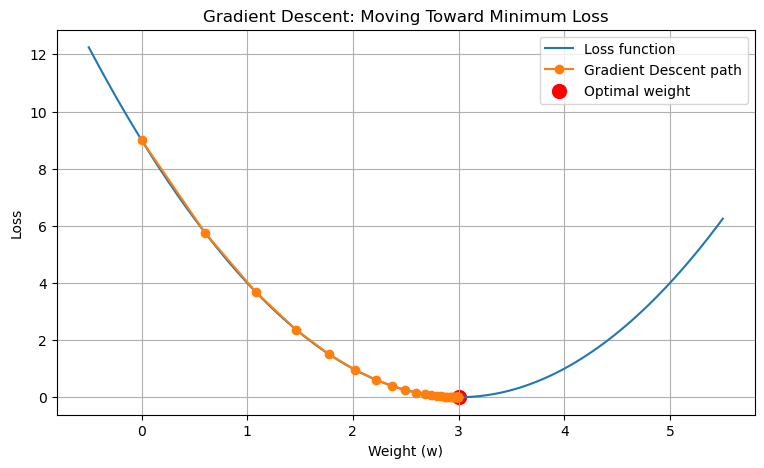

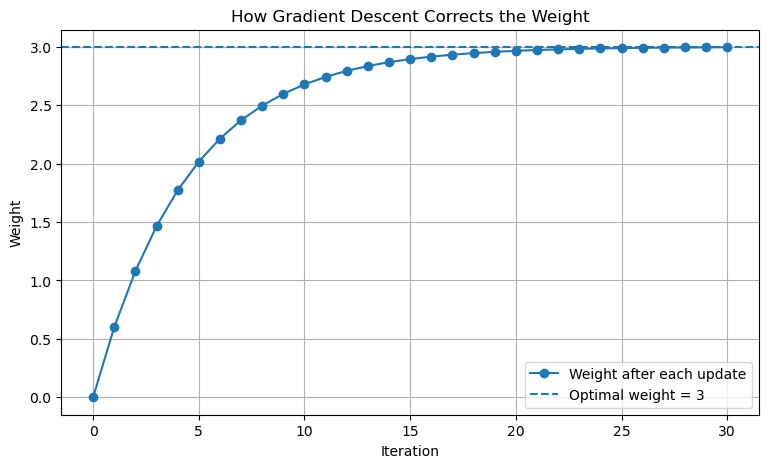


Final weight: 2.996286179882144
Final loss: 1.3792459867793054e-05


In [2]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Define the loss function
def loss(w):
    return (w - 3) ** 2

# 2. Calculate the gradient (derivative)
def gradient(w):
    return 2 * (w - 3)

# 3. Initialize parameters
w = 0.0
learning_rate = 0.1
epochs = 30

weights = [w]
losses = [loss(w)]

# 4. Run Gradient Descent
for i in range(epochs):
    grad = gradient(w)

    # Correct the weight
    w = w - learning_rate * grad

    weights.append(w)
    losses.append(loss(w))

    print(
        f"Step {i + 1:2d}: "
        f"Gradient = {grad:8.4f}, "
        f"Weight = {w:.6f}, "
        f"Loss = {loss(w):.6f}"
    )

# 5. Plot the loss curve
w_values = np.linspace(-0.5, 5.5, 300)

plt.figure(figsize=(9, 5))
plt.plot(w_values, loss(w_values), label="Loss function")
plt.plot(weights, losses, "o-", label="Gradient Descent path")
plt.scatter(3, 0, color="red", s=100, label="Optimal weight")
plt.xlabel("Weight (w)")
plt.ylabel("Loss")
plt.title("Gradient Descent: Moving Toward Minimum Loss")
plt.legend()
plt.grid(True)
plt.show()

# 6. Plot weight correction
plt.figure(figsize=(9, 5))
plt.plot(range(len(weights)), weights, "o-", label="Weight after each update")
plt.axhline(3, linestyle="--", label="Optimal weight = 3")
plt.xlabel("Iteration")
plt.ylabel("Weight")
plt.title("How Gradient Descent Corrects the Weight")
plt.legend()
plt.grid(True)
plt.show()

print("\nFinal weight:", w)
print("Final loss:", loss(w))


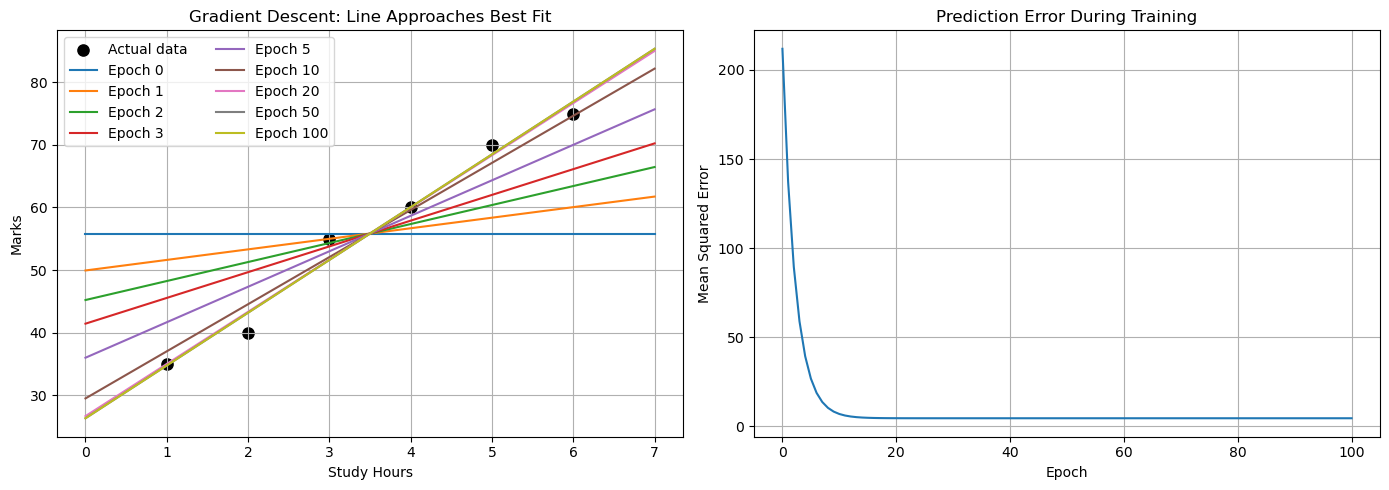

Best-fit equation:
Marks = 8.429 * Hours + 26.333
Final MSE: 4.6032


In [3]:

import numpy as np
import matplotlib.pyplot as plt

# 1. Sample training data
X = np.array([1, 2, 3, 4, 5, 6], dtype=float)
y = np.array([35, 40, 55, 60, 70, 75], dtype=float)

# 2. Standardize input for stable learning
X_mean = X.mean()
X_std = X.std()
X_scaled = (X - X_mean) / X_std

# 3. Initialize weight and bias
w = 0.0
b = y.mean()  # Start near the average target
learning_rate = 0.1
epochs = 100

n = len(X)
losses = []
saved_lines = {}

# 4. Train using Gradient Descent
for epoch in range(epochs + 1):
    predictions = w * X_scaled + b
    error = predictions - y
    mse = np.mean(error ** 2)

    losses.append(mse)

    # Save selected stages for visualization
    if epoch in [0, 1, 2, 3, 5, 10, 20, 50, 100]:
        saved_lines[epoch] = (w, b)

    # Calculate gradients
    dw = (2 / n) * np.sum(error * X_scaled)
    db = (2 / n) * np.sum(error)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

# 5. Convert learned model back to original X scale
final_slope = w / X_std
final_intercept = b - final_slope * X_mean

# 6. Plot the changing regression line
x_plot = np.linspace(0, 7, 200)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X, y, color="black", s=65, label="Actual data")

for epoch, (weight, bias) in saved_lines.items():
    slope = weight / X_std
    intercept = bias - slope * X_mean

    axes[0].plot(
        x_plot,
        slope * x_plot + intercept,
        label=f"Epoch {epoch}"
    )

axes[0].set_title("Gradient Descent: Line Approaches Best Fit")
axes[0].set_xlabel("Study Hours")
axes[0].set_ylabel("Marks")
axes[0].legend(ncol=2)
axes[0].grid(True)

# 7. Plot the loss reduction
axes[1].plot(range(epochs + 1), losses)
axes[1].set_title("Prediction Error During Training")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Mean Squared Error")
axes[1].grid(True)

plt.tight_layout()
plt.show()

print("Best-fit equation:")
print(f"Marks = {final_slope:.3f} * Hours + {final_intercept:.3f}")
print(f"Final MSE: {losses[-1]:.4f}")
